# Explaining single forecasts

The LightGBM models of notebooks 02 and 03 give a number, e.g. "6,091 trips tomorrow", but not
*why*. This notebook takes single forecasts apart with **SHAP values** (SHapley Additive
exPlanations): each forecast becomes a base value plus one contribution per feature.

- The **base value** is the mean prediction over the training data on the log scale: turned back into trips, a geometric mean, a little below the average day. The pages call it the model's starting point.
- A **contribution** says how far a feature moves this forecast away from the base value.
- The contributions add up **exactly** to the forecast, nothing is left unexplained.

The idea comes from game theory (Shapley values): a feature gets its average added contribution
over all orders in which the features could be added. For tree models this can be computed
exactly and fast (TreeSHAP), and LightGBM does it itself: `predict(X, pred_contrib=True)`.

The models predict `log(count)`, so the contributions add up on the log scale and become
**factors** on the count: forecast = base × factor 1 × factor 2 × … The functions in
`radmuenster.explain` sum the features into five groups (six in the global model), which are
easier to read and, as section 4 shows, less arbitrary than single features.

**SHAP explains the model, not the traffic.** "Weather −22 %" means: this is how the model weighed
the weather. Whether rain *causes* 22 % fewer trips is another question.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from radmuenster.data import DEFAULT_SITE, load_intervals, to_daily
from radmuenster.explain import GROUP_LABELS, GROUPS, explain_global, explain_lightgbm, reasons_text
from radmuenster.explore import PALETTE
from radmuenster.features import PERIOD_STARTS, training_table
from radmuenster.models import _lightgbm_inputs, fit_lightgbm
from radmuenster.multi_site import fit_global_lightgbm, site_counts_by_id, sites_table
from radmuenster.sites import SITES_BY_ID, load_all_sites
from radmuenster.weather import load_weather

RAW = Path("..") / "data" / "raw"
daily = to_daily(load_intervals(DEFAULT_SITE, cache_dir=RAW))
weather = load_weather(end=daily.index.max().date(), cache_dir=RAW / "weather")

# Trained on everything before 2026, explained on 2026: forecasts the model has not seen,
# as in the cross-validation (training on all days would explain fitted values instead)
TEST_START = pd.Timestamp("2026-01-01")
table = training_table(daily, weather)
train, test = table[table.index < TEST_START], table[table.index >= TEST_START]
model, factors = fit_lightgbm(train)
explanation = explain_lightgbm(model, factors, test.drop(columns="count"))
explanation["actual"] = test["count"]
GROUP_COLUMNS = [group for group in GROUPS if group in explanation]
print(f"{len(test)} days from {test.index.min():%Y-%m-%d} to {test.index.max():%Y-%m-%d}")
print(f"Base value: {explanation['base'].iloc[0]:,.0f} trips")

280 days from 2026-01-01 to 2026-11-16
Base value: 5,556 trips


## 1. One forecast, taken apart

Three days of October 2026 at the Warendorfer Straße: a dry workday, a workday with 21 hours of
rain and a public holiday on a Saturday (Day of German Unity). Each bar starts where the previous
one ended; the last bar is the forecast, the dot the count.

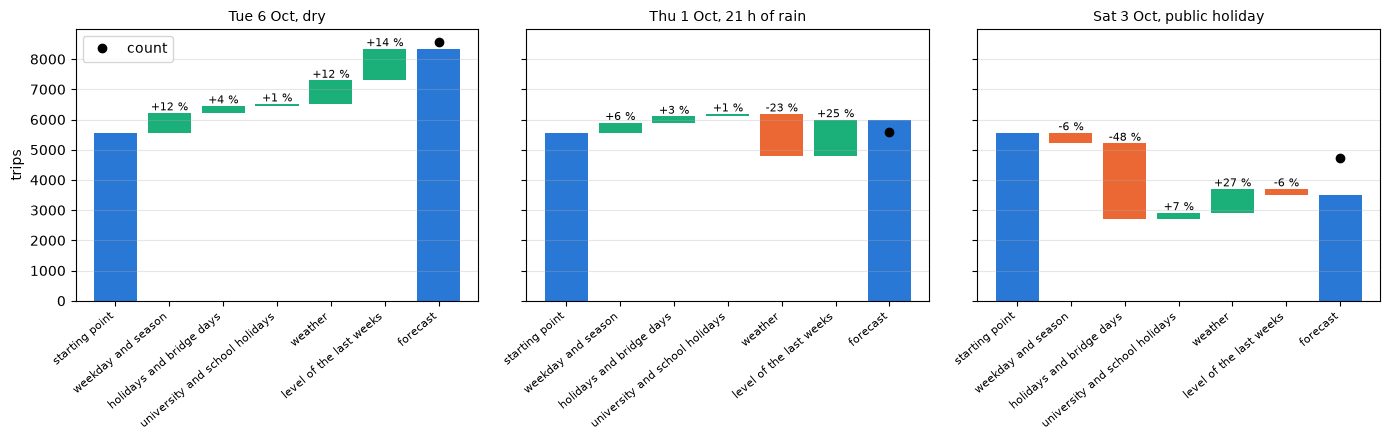

2026-10-06 Compared with the model's starting point (5,556 trips): level of the last weeks +14 %, weather +12 %, weekday and season +12 %.
2026-10-01 Compared with the model's starting point (5,556 trips): weather -23 %, level of the last weeks +25 %, weekday and season +6 %.
2026-10-03 Compared with the model's starting point (5,556 trips): holidays and bridge days -48 %, weather +27 %, university and school holidays +7 %.


In [2]:
def waterfall(ax, row, title):
    # Bars from the base over each group to the forecast, on the count
    level = row["base"]
    ax.bar(0, level, color=PALETTE["light"][0])
    for i, group in enumerate(GROUP_COLUMNS, start=1):
        new = level * row[group]
        color = PALETTE["light"][2] if new >= level else PALETTE["light"][1]
        ax.bar(i, new - level, bottom=level, color=color)
        ax.text(i, max(level, new), f"{(row[group] - 1) * 100:+.0f} %", ha="center", va="bottom", fontsize=8)
        level = new
    end = len(GROUP_COLUMNS) + 1
    ax.bar(end, level, color=PALETTE["light"][0])
    ax.plot(end, row["actual"], "o", color="black", label="count")
    ax.set_xticks(range(end + 1), ["starting point", *(GROUP_LABELS[g] for g in GROUP_COLUMNS), "forecast"],
                  rotation=40, ha="right", fontsize=8)
    ax.set_title(title, fontsize=10)
    ax.grid(axis="y", alpha=0.3)

DAYS = {
    "2026-10-06": "Tue 6 Oct, dry",
    "2026-10-01": "Thu 1 Oct, 21 h of rain",
    "2026-10-03": "Sat 3 Oct, public holiday",
}
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)
for ax, (day, title) in zip(axes, DAYS.items()):
    waterfall(ax, explanation.loc[day], title)
axes[0].set_ylabel("trips")
axes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()

for day in DAYS:
    print(day, reasons_text(explanation.loc[day]))

In [3]:
# The factors multiply exactly to the forecast of the model
groups_product = explanation[GROUP_COLUMNS].prod(axis=1)
print("largest difference:", (explanation["base"] * groups_product - explanation["prediction"]).abs().max())

largest difference: 0.0


The dry Tuesday is a busy day for three reasons of similar size: a workday in term time, good
weather and a high level in the last weeks. On the rainy Thursday the weather takes about a fifth
off. Weather factors above 1 on dry days are not a mistake: the base is a day with *average*
weather, and that includes rainy days.

The holiday is the interesting one: the model takes off half, as on a holiday on a workday, and
forecasts about 3,500 trips; the count was about 4,700. Section 6 comes back to it.

## 2. Which features matter? SHAP against the gain of the trees

Notebook 02 showed the **gain** of LightGBM: how much the splits on a feature improved the fit
during training. The mean absolute SHAP value measures something else: how far a feature moves
the forecasts, here the 2026 test days.

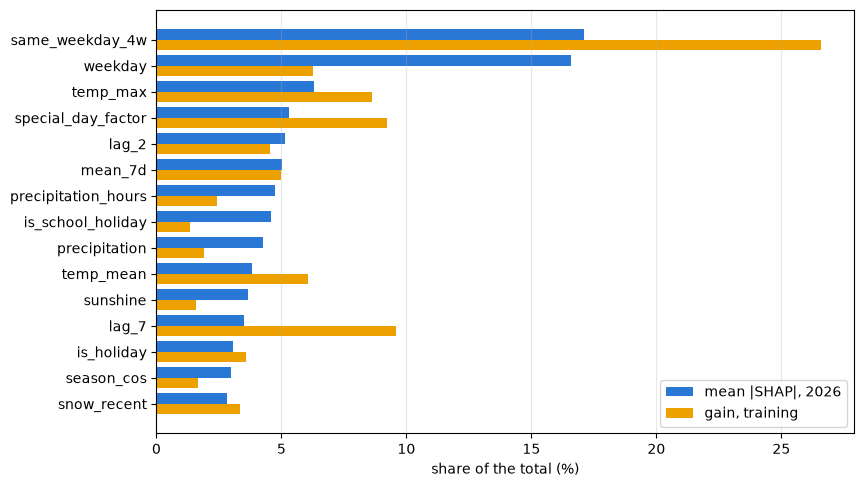

In [4]:
inputs = _lightgbm_inputs(test.drop(columns="count"), factors)
contributions = pd.DataFrame(model.predict(inputs, pred_contrib=True), index=inputs.index,
                             columns=[*inputs.columns, "base"]).drop(columns="base")
shap_share = contributions.abs().mean()
gain = pd.Series(model.booster_.feature_importance("gain"), index=model.booster_.feature_name())
importance = pd.DataFrame({"mean |SHAP|": shap_share / shap_share.sum(), "gain": gain / gain.sum()})
importance = importance.sort_values("mean |SHAP|", ascending=False).head(15)

fig, ax = plt.subplots(figsize=(9, 5.5))
y = np.arange(len(importance))
ax.barh(y - 0.2, importance["mean |SHAP|"] * 100, height=0.4, color=PALETTE["light"][0], label="mean |SHAP|, 2026")
ax.barh(y + 0.2, importance["gain"] * 100, height=0.4, color=PALETTE["light"][3], label="gain, training")
ax.set_yticks(y, importance.index)
ax.invert_yaxis()
ax.set_xlabel("share of the total (%)")
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.3)
plt.show()

Both put the mean of the last four same weekdays (`same_weekday_4w`) first, but they disagree
on much else. The weekday moves the forecasts more than twice as much as its gain suggests: a
few splits on it settle a large effect. The school holidays and the rain hours move the forecasts
more than their gain, `lag_7` less: the trees split on it often, but in small steps that refine
`same_weekday_4w`. The gain is a statement about the training, SHAP about the forecasts, and
for the question "why this forecast" only the second answers.

## 3. Groups instead of single features

The groups and their features:

In [5]:
pd.DataFrame({"label": GROUP_LABELS, "features": {g: ", ".join(f) for g, f in GROUPS.items()}})

,label,features
weekday_season,weekday and season,"weekday, month, season_sin, season_cos"
holidays,holidays and bridge days,"is_holiday, is_bridge_day, is_christmas, is_ro..."
uni_school,university and school holidays,"is_lecture_period, is_school_holiday"
weather,weather,"temp_mean, temp_max, precipitation, precipitat..."
recent_level,level of the last weeks,"lag_2, lag_7, lag_14, lag_364, mean_7d, same_w..."
this_site,this site,site


## 4. Correlated features share their effect

`same_weekday_4w` is the mean of the last four same weekdays: a Sunday has low Sundays before it.
So the feature already knows the weekday, the season and the measurement period, and the trees
can take the Sunday effect from it or from the weekday. The mean factor per weekday shows how
the model has split it:

In [6]:
logs = np.log(explanation[GROUP_COLUMNS])
by_weekday = np.exp(logs.groupby(explanation.index.dayofweek).mean())
by_weekday.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
by_weekday.rename(columns=GROUP_LABELS).round(2)

,weekday and season,holidays and bridge days,university and school holidays,weather,level of the last weeks
Mon,1.07,1.00,1.0,1.01,1.04
Tue,1.12,1.04,1.0,1.02,1.05
Wed,1.11,1.04,1.0,1.00,1.13
Thu,1.07,0.99,1.0,0.98,1.11
Fri,1.03,0.99,1.0,1.01,1.09
Sat,0.94,1.01,1.0,0.98,0.95
Sun,0.75,1.01,1.0,0.99,0.64


In [7]:
period = np.exp(contributions["period"])
print(f"Factor of the measurement period on the 2026 test days: {period.min():.3f} to {period.max():.3f}")

Factor of the measurement period on the 2026 test days: 0.977 to 1.014


The Sunday is split almost evenly: about −25 % under weekday and season, about −35 % under the
level of the last weeks. Neither number alone is "the Sunday effect", only both together. The
same goes for the measurement period: since October 2025 the site counts about 40 % more (see
the exploratory analysis), but the period feature contributes almost nothing in 2026. The recent
counts have carried the new level for months, so the trees no longer need the period.

That is why the app shows groups and why the level of the last weeks includes the period. Within
a group the split is arbitrary, between the groups much less so. It is still not a measurement:
another model with the same accuracy could split weekday and recent level differently.

## 5. Weather: rain hours and the weather factor

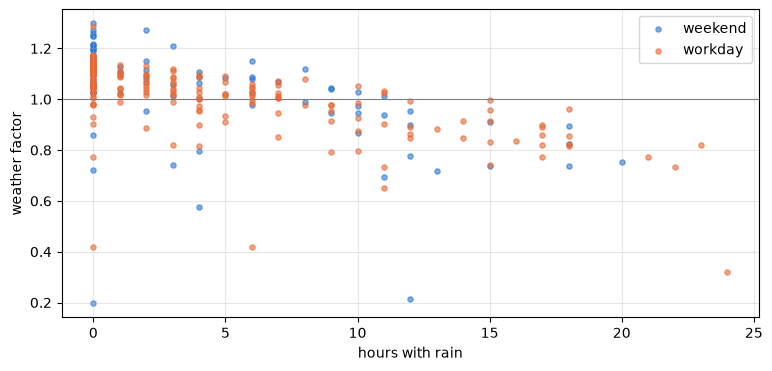

day,weekend,workday
rain hours (binned),,
0,1.13,1.11
0-2,1.11,1.07
2-5,1.06,1.02
5-8,1.08,1.01
8-12,0.95,0.92
12+,0.75,0.84


In [8]:
rain = pd.DataFrame({
    "rain hours": test["precipitation_hours"],
    "weather factor": explanation["weather"],
    "day": np.where(test.index.dayofweek >= 5, "weekend", "workday"),
})
rain["rain hours (binned)"] = pd.cut(rain["rain hours"], [-0.1, 0, 2, 5, 8, 12, 24],
                                     labels=["0", "0-2", "2-5", "5-8", "8-12", "12+"])

fig, ax = plt.subplots(figsize=(9, 4))
for color, (kind, rows) in zip(PALETTE["light"], rain.groupby("day")):
    ax.scatter(rows["rain hours"], rows["weather factor"], s=14, alpha=0.6, color=color, label=kind)
ax.axhline(1, color="grey", lw=0.8)
ax.set_xlabel("hours with rain")
ax.set_ylabel("weather factor")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

rain.pivot_table(index="rain hours (binned)", columns="day", values="weather factor",
                 aggfunc="median", observed=True).round(2)

From a dry day (about 1.12) to more than 12 hours of rain, the weather factor falls to about 0.85
on workdays and about 0.75 at weekends. That matches the insights (rain costs more at weekends,
leisure trips), though with only a few long rainy weekend days in 2026. Part of such an
interaction may also sit in the weekday group: TreeSHAP splits the effect of two features that
act together between both of them. The points far below the rest are snow days of January 2026.

### Where the model went wrong

The largest errors of 2026, with their explanation:

In [9]:
errors = explanation.assign(error=explanation["prediction"] / explanation["actual"] - 1)
worst = errors.reindex(errors["error"].abs().sort_values(ascending=False).index).head(8)
worst[["base", *GROUP_COLUMNS, "prediction", "actual", "error"]].rename(columns=GROUP_LABELS).round(2)

,base,weekday and season,holidays and bridge days,university and school holidays,weather,level of the last weeks,prediction,actual,error
date,,,,,,,,,
2026-01-11,5556.35,0.87,1.02,1.01,0.20,0.50,487.47,1527,-0.68
2026-06-04,5556.35,1.02,0.51,1.11,1.00,1.17,3743.26,2304,0.62
2026-01-06,5556.35,1.05,1.04,0.94,0.42,0.86,2064.23,5014,-0.59
2026-01-03,5556.35,0.91,1.04,0.94,0.74,0.93,3362.70,2141,0.57
2026-01-10,5556.35,1.05,1.03,1.02,0.21,0.85,1106.73,2368,-0.53
2026-01-12,5556.35,1.15,1.04,1.04,0.80,1.07,5856.39,3827,0.53
2026-01-29,5556.35,1.13,1.04,1.03,0.32,1.12,2415.64,5112,-0.53
2026-06-07,5556.35,0.64,1.02,1.02,1.05,0.95,3728.47,2452,0.52


Five of the eight worst days are snow days of January 2026 with a weather factor of 0.2 to 0.4:
the model forecasts a third to a half of the real count. Snow days are rare in the training data,
and the model has learned that snow empties the streets; in January 2026 more people kept cycling.
On two other January days (3 and 12 January) it was the other way round. On 4 June (Corpus
Christi) the holiday factor of 0.51 was not enough. The explanation shows at once which input is
to blame; without it the error would only be a large number.

## 6. Holidays and bridge days

In [10]:
special = test[(test["is_holiday"] > 0) | (test["is_bridge_day"] > 0)]
pd.DataFrame({
    "weekday": special.index.day_name(),
    "kind": np.where(special["is_holiday"] > 0, "holiday", "bridge day"),
    "holidays factor": explanation.loc[special.index, "holidays"].round(2),
    "forecast": explanation.loc[special.index, "prediction"].round(),
    "count": special["count"],
})

,weekday,kind,holidays factor,forecast,count
date,,,,,
2026-01-01,Thursday,holiday,0.36,1058.0,1133
2026-01-02,Friday,bridge day,1.01,3899.0,2663
2026-04-03,Friday,holiday,0.39,1796.0,2041
2026-04-06,Monday,holiday,0.39,1784.0,2124
2026-05-01,Friday,holiday,0.50,4645.0,4515
2026-06-04,Thursday,holiday,0.51,3743.0,2304
2026-06-05,Friday,bridge day,0.99,7048.0,5769
2026-10-03,Saturday,holiday,0.52,3489.0,4728
2026-11-01,Sunday,holiday,0.68,2834.0,2700


Two weaknesses the error statistics alone do not show:

- **A holiday on a weekend** gets nearly the same factor as on a workday (0.52 on Saturday,
  3 October). On a Saturday there are few commuters to lose, so the model takes off too much.
  `special_day_factor` comes from the holiday baseline, which does not know the weekday.
- **Bridge days** get a factor of about 1.0: the model ignores them (2 January, 5 June) and
  forecasts too many trips. With about 20 bridge days in the training data, no tree has split on
  `is_bridge_day` (its gain is 0), and their factor in `special_day_factor` was not enough either.

Both are ideas for a later model change (e.g. the holiday factor per weekday), not part of this step.

## 7. All sites: the global model

The global model forecasts all 23 sites (notebook 03). It works on counts divided by the median
of each site, so its explanation starts from a usual day *at this site*, and it has a sixth group:
the site itself, for what remains specific to a site.

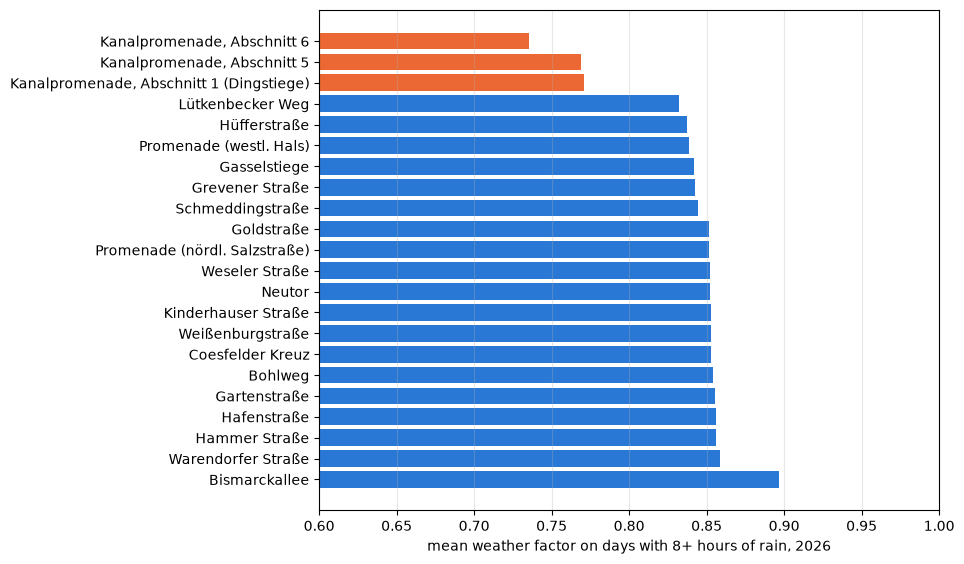

In [11]:
all_sites, failed = load_all_sites(cache_dir=RAW)
assert not failed, failed
counts = site_counts_by_id(all_sites, daily)
sites = sites_table(counts, weather, {DEFAULT_SITE: PERIOD_STARTS})
global_model = fit_global_lightgbm(sites[sites.index < TEST_START])
sites_test = sites[(sites.index >= TEST_START) & sites["site"].isin(global_model.scale.index)]

site_explanation = explain_global(global_model, sites_test.drop(columns="count"))
site_explanation["name"] = sites_test["site"].map(lambda site: SITES_BY_ID[site].name).to_numpy()
site_explanation["rain hours"] = sites_test["precipitation_hours"].to_numpy()
site_explanation["actual"] = sites_test["count"].to_numpy()
SITE_GROUPS = [group for group in GROUPS if group in site_explanation]

rainy = site_explanation[site_explanation["rain hours"] >= 8]
rain_by_site = np.exp(np.log(rainy["weather"]).groupby(rainy["name"]).mean()).sort_values()

fig, ax = plt.subplots(figsize=(8, 6.5))
colors = [PALETTE["light"][1] if "Kanalpromenade" in name else PALETTE["light"][0] for name in rain_by_site.index]
ax.barh(rain_by_site.index, rain_by_site, color=colors)
ax.invert_yaxis()
ax.set_xlim(0.6, 1)
ax.set_xlabel("mean weather factor on days with 8+ hours of rain, 2026")
ax.grid(axis="x", alpha=0.3)
plt.show()

In [12]:
# A rainy Sunday in the autumn holidays: 25 October 2026
day = site_explanation.loc["2026-10-25"].set_index("name")
day[["base", *SITE_GROUPS, "prediction", "actual"]].rename(columns=GROUP_LABELS).sort_values("weather").round(2)

,base,weekday and season,holidays and bridge days,university and school holidays,weather,level of the last weeks,this site,prediction,actual
name,,,,,,,,,
"Kanalpromenade, Abschnitt 6",442.37,0.90,1.03,0.98,0.62,1.06,1.11,293.04,204.0
"Kanalpromenade, Abschnitt 5",815.05,0.79,1.03,0.98,0.65,1.08,0.92,425.18,396.0
"Kanalpromenade, Abschnitt 1 (Dingstiege)",1185.97,0.83,1.03,0.98,0.66,1.06,0.98,680.14,543.0
Lütkenbecker Weg,3037.48,0.80,1.03,0.97,0.72,0.59,0.96,1001.93,876.0
Hüfferstraße,4629.21,0.82,1.03,0.98,0.73,0.68,0.96,1823.31,2074.0
Bismarckallee,4987.34,0.81,1.03,0.98,0.73,0.64,0.98,1873.56,1900.0
Promenade (westl. Hals),8958.52,0.84,1.03,0.98,0.74,0.65,1.01,3637.76,3885.0
Gasselstiege,2574.82,0.83,1.03,0.98,0.74,0.59,1.02,955.87,998.0
Grevener Straße,1283.44,0.75,1.03,0.98,0.74,0.66,1.02,490.34,633.0


The model has learned that rain costs more on the three sections of the Kanalpromenade, leisure
routes along the canal: their weather factor on rainy days is about 0.75, at the other sites
about 0.85. On the rainy Sunday of 25 October the difference is larger, about 0.64 against 0.75.
The level of the last weeks also differs: at the commuter sites it is far below 1 on a Sunday
(the last Sundays were low), on the Kanalpromenade about 1 (Sundays are normal days there).

This answers the question Leeze AI could not answer before ("why do the Kanalpromenaden drop more
than the Warendorfer Straße?") from the model itself, not only from the insights.

## 8. What goes into the app

- **Per forecast:** base value and one factor per group, written by the evening run together
  with the forecast, for all sites; never computed again later, so that the explanation always
  belongs to the published number.
- **Text:** the two or three groups that move the forecast most (`reasons_text`), labelled as
  how the model weighed its inputs.
- **Caveats** in "How it works": groups instead of features because of correlated inputs (section 4);
  an explanation is not a cause.